In [1]:
# ==============================================
# SIMULATION GROUND TRUTH — ANALYST CHEAT SHEET
# ==============================================
# Segment split: Low 50%, Medium 35%, High 15%
# Offer split: 10% Control, 30% each offer
# 
# Conversion probabilities (responses table):
# Segment  | Discount | FreeTrial | EarlyAccess | Control
# Low      |   0.17   |   0.20    |    0.15     |  0.06
# Medium   |   0.18   |   0.15    |    0.12     |  0.08
# High     |   0.22   |   0.24    |    0.30     |  0.10
#
# Watch probability by segment (views table):
# Low: 15% of days, Medium: 35%, High: 60%
# ==============================================

# Imports

In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

np.random.seed(42)



# Customer Table

| Column | Type | Description |
|---|---|---|
| cust_id | int | Unique customer identifier |
| segment | string | Low / Medium / High — based on pre-churn watch hours |
| avg_weekly_hours_pre | float | Average weekly watch hours in 6 months before churning |
| offer | string | Offer assigned — Discount / FreeTrial / EarlyAccess / Control |

In [3]:
n = 500000

# Step 1: Create equal segments
segments = np.random.choice(['Low', 'Medium', 'High'], size=n, p=[0.50, 0.35, 0.15])
    
cust_df = pd.DataFrame({
    'customer_id': np.arange(1, n + 1),
    'segment': segments
})

# Step 2: Assign offers WITHIN each segment
offers = []

for seg in ['High', 'Medium', 'Low']:
    seg_size = (cust_df['segment'] == seg).sum()
    
    # 10% control (offer 4), 30% each for 1,2,3
    seg_offers = (
        ['Control'] * int(0.10 * seg_size) +
        ['Discount'] * int(0.30 * seg_size) +
        ['Free Trial'] * int(0.30 * seg_size) +
        ['Early Access'] * int(0.30 * seg_size)
    )
    
    # Adjust for rounding
    while len(seg_offers) < seg_size:
        seg_offers.append(np.random.choice(['Discount', 'Free Trial', 'Early Access']))
    
    np.random.shuffle(seg_offers)
    offers.extend(seg_offers)

cust_df['offer'] = offers

# Step 3: Generate avg_weekly_hours_pre based on segment
choices = [
    np.random.lognormal(0.5, 0.5, n),
    np.random.lognormal(1.5, 0.5, n),
    np.random.lognormal(2.5, 0.5, n),
]
cust_df['avg_weekly_hours_pre'] = np.select(
    condlist=[
        cust_df['segment'] == 'Low',
        cust_df['segment'] == 'Medium',
        cust_df['segment'] == 'High'
    ],
    choicelist=choices,
    default=np.nan
)

cust_df.head()

,customer_id,segment,offer,avg_weekly_hours_pre
0,1,Low,Free Trial,1.205087
1,2,High,Free Trial,9.673556
2,3,Medium,Free Trial,3.064467
3,4,Medium,Discount,9.936197
4,5,Low,Discount,0.744099


In [4]:
cust_df['offer'].value_counts()

offer
Free Trial      150001
Early Access    150001
Discount        150000
Control          49998
Name: count, dtype: int64

In [5]:
cust_df['segment'].value_counts()

segment
Low       249555
Medium    175398
High       75047
Name: count, dtype: int64

In [6]:
cust_df[['segment', 'offer']].value_counts()

segment  offer       
Low      Free Trial      74967
         Discount        74962
         Early Access    74858
Medium   Early Access    52619
         Discount        52570
         Free Trial      52524
Low      Control         24768
High     Early Access    22524
         Free Trial      22510
         Discount        22468
Medium   Control         17685
High     Control          7545
Name: count, dtype: int64

In [7]:
print(cust_df['segment'].value_counts(normalize=True).round(3))
print(cust_df.groupby('segment')['offer'].value_counts(normalize=True).round(3))

segment
Low       0.499
Medium    0.351
High      0.150
Name: proportion, dtype: float64
segment  offer       
High     Early Access    0.300
         Free Trial      0.300
         Discount        0.299
         Control         0.101
Low      Free Trial      0.300
         Discount        0.300
         Early Access    0.300
         Control         0.099
Medium   Early Access    0.300
         Discount        0.300
         Free Trial      0.299
         Control         0.101
Name: proportion, dtype: float64


In [8]:
print(cust_df.groupby('segment')['avg_weekly_hours_pre'].describe().round(2))

            count   mean   std   min   25%    50%    75%     max
segment                                                         
High      75047.0  13.81  7.34  1.53  8.71  12.20  17.08  104.73
Low      249555.0   1.87  0.99  0.16  1.18   1.65   2.31   16.27
Medium   175398.0   5.07  2.70  0.42  3.19   4.48   6.27   39.90


In [9]:
os.makedirs('../data/raw', exist_ok=True)
cust_df.to_csv('../data/raw/customers.csv', index=False)

# Response Data

| Column | Type | Description |
|---|---|---|
| cust_id | int | Links to customers.csv |
| offer | string | Offer received |
| segment | string | Segment - repeated here for convenience |
| resubscribed_promo | int | Did they resubscribe during promo period? (1/0) |
| resubscribed_day | int | Day of resubscription (1–90, null if no resubscription) |

In [10]:
# Getting customer data from previous step
cust_df = pd.read_csv('../data/raw/customers.csv')
cust_df.head()

,customer_id,segment,offer,avg_weekly_hours_pre
0,1,Low,Free Trial,1.205087
1,2,High,Free Trial,9.673556
2,3,Medium,Free Trial,3.064467
3,4,Medium,Discount,9.936197
4,5,Low,Discount,0.744099


In [11]:
# Example: define response rates for each segment x offer
response_rates = {
    ('Low', 'Discount'): 0.17,
    ('Low', 'Free Trial'): 0.20,
    ('Low', 'Early Access'): 0.15,
    ('Low', 'Control'): 0.06,
    
    ('Medium', 'Discount'): 0.18,
    ('Medium', 'Free Trial'): 0.15,
    ('Medium', 'Early Access'): 0.12,
    ('Medium', 'Control'): 0.08,
    
    ('High', 'Discount'): 0.22,
    ('High', 'Free Trial'): 0.24,
    ('High', 'Early Access'): 0.30,
    ('High', 'Control'): 0.10,
}

# Step 1: Map probabilities to each row
cust_df['response_prob'] = cust_df[['segment', 'offer']].apply(tuple, axis=1).map(response_rates)

# Step 2: Simulate resubscription (Bernoulli draw)
cust_df['resubscribed_promo'] = np.random.binomial(1, cust_df['response_prob'].values, size=len(cust_df))

# Step 3: Simulate day of resubscription (only if resubscribed)
resub_days = np.random.geometric(p=0.05, size=len(cust_df))
resub_days = np.clip(resub_days, 1, 90)

cust_df['resub_day'] = np.where(
    cust_df['resubscribed_promo'] == 1,
    resub_days,
    np.nan
)

cust_df.head()

,customer_id,segment,offer,avg_weekly_hours_pre,response_prob,resubscribed_promo,resub_day
0,1,Low,Free Trial,1.205087,0.20,1,6.0
1,2,High,Free Trial,9.673556,0.24,1,2.0
2,3,Medium,Free Trial,3.064467,0.15,0,NaN
3,4,Medium,Discount,9.936197,0.18,1,33.0
4,5,Low,Discount,0.744099,0.17,0,NaN


In [12]:
cust_df.groupby(['segment', 'offer'])['resubscribed_promo'].mean()

segment  offer       
High     Control         0.098741
         Discount        0.220447
         Early Access    0.299192
         Free Trial      0.244780
Low      Control         0.059230
         Discount        0.171167
         Early Access    0.150966
         Free Trial      0.198447
Medium   Control         0.078993
         Discount        0.179380
         Early Access    0.121458
         Free Trial      0.152597
Name: resubscribed_promo, dtype: float64

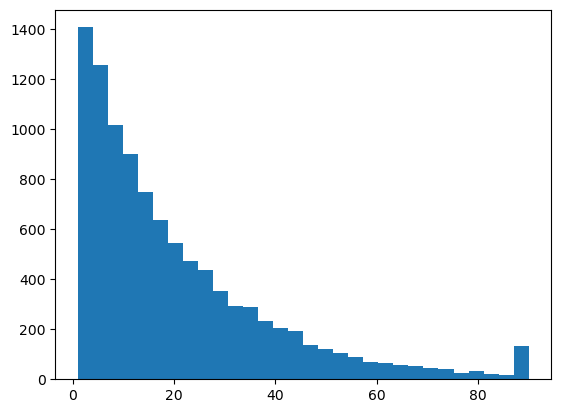

Mean day: 20.1


In [13]:
sample_days = np.random.geometric(p=0.05, size=10000)
sample_days = np.clip(sample_days, 1, 90)
plt.hist(sample_days, bins=30)
plt.show()
print(f"Mean day: {sample_days.mean():.1f}")

In [14]:
responses_df = cust_df[['customer_id', 'segment', 'offer', 'resubscribed_promo', 'resub_day']]
responses_df.sample(5)

,customer_id,segment,offer,resubscribed_promo,resub_day
14954,14955,Medium,Discount,0,NaN
279000,279001,Medium,Early Access,0,NaN
51618,51619,Low,Control,0,NaN
242948,242949,Medium,Control,0,NaN
261589,261590,Low,Early Access,0,NaN


In [15]:
print(responses_df.groupby(['segment', 'offer'])['resubscribed_promo'].mean().unstack().round(3))

offer    Control  Discount  Early Access  Free Trial
segment                                             
High       0.099     0.220         0.299       0.245
Low        0.059     0.171         0.151       0.198
Medium     0.079     0.179         0.121       0.153


In [16]:
responses_df.to_csv('../data/raw/responses.csv', index=False)

# Views Table

| Column | Type | Description |
|---|---|---|
| cust_id | int | Links to customers.csv |
| day | int | Day number in measurement window (1–90) |
| hours_watched | float | Hours watched that day |

In [17]:
# Getting response data from previous step
base_df = pd.read_csv('../data/raw/responses.csv')
base_df.head()

,customer_id,segment,offer,resubscribed_promo,resub_day
0,1,Low,Free Trial,1,6.0
1,2,High,Free Trial,1,2.0
2,3,Medium,Free Trial,0,NaN
3,4,Medium,Discount,1,33.0
4,5,Low,Discount,0,NaN


In [18]:
base_df['resubscribed_promo'].value_counts()

resubscribed_promo
0    416344
1     83656
Name: count, dtype: int64

In [19]:
base_df.drop(base_df[base_df['resubscribed_promo'] == 0].index, inplace=True)
base_df.shape

(83656, 5)

In [20]:
# Define segment-level parameters
watch_probs = {
    'Low': 0.15,
    'Medium': 0.35,
    'High': 0.60
}

lognormal_params = {
    'Low': (0.5, 0.5),
    'Medium': (1.5, 0.5),
    'High': (2.5, 0.5)
}

views_data = []

for _, row in base_df.iterrows():
    cust_id = row['customer_id']
    segment = row['segment']
    mean, sigma = lognormal_params[segment]

    for day in range(1, 91):
        watched = np.random.binomial(1, watch_probs[segment])
        if watched:
            hours = np.random.lognormal(mean, sigma)
            views_data.append((cust_id, day, hours))

# Create final dataframe
views_df = pd.DataFrame(views_data, columns=['customer_id', 'day', 'hours_watched'])

views_df.head()

,customer_id,day,hours_watched
0,1,1,0.764468
1,1,2,0.879050
2,1,3,2.737310
3,1,9,1.027879
4,1,11,1.813813


In [21]:
print(f"Total view records: {len(views_df):,}")
print(views_df.groupby(
    views_df['customer_id'].map(base_df.set_index('customer_id')['segment'])
)['hours_watched'].describe().round(2))

Total view records: 2,308,938
                count   mean   std   min   25%    50%    75%     max
customer_id                                                         
High         968442.0  13.80  7.35  1.29  8.69  12.18  17.06  116.94
Low          546976.0   1.87  1.00  0.16  1.18   1.65   2.31   16.80
Medium       793520.0   5.08  2.71  0.40  3.20   4.48   6.29   46.49


In [22]:
views_df.to_csv('../data/raw/views.csv', index=False)